In [1]:
import numpy as np
from sklearn.model_selection import cross_validate, LeaveOneGroupOut
from sklearn.ensemble import HistGradientBoostingRegressor
import matplotlib.pyplot as plt
import xgboost as xgb


import yaml
import pandas as pd
import os

In [2]:
config_path = os.path.join('..', 'configs', 'global_config.yaml')
with open(config_path) as f:
    config = yaml.safe_load(f)

seed = config["seed"]
print(seed)

5


In [3]:
# read prediction and spread from ensemble modeling
ensemble_df = pd.read_csv('Eg_XGB_ensemble_pred_spread.csv')

In [4]:
from scipy.stats import spearmanr

In [5]:
ensemble_df.columns

Index(['Unnamed: 0', 'formula', 'B_pair', 'Eg_true', 'gcv_gbag_pred',
       'gcv_gbag_spread', 'gcv_gbag_fold', 'rcv_gbag_pred', 'rcv_gbag_spread',
       'rcv_gbag_fold', 'gcv_rbag_pred', 'gcv_rbag_spread', 'gcv_rbag_fold',
       'rcv_rbag_pred', 'rcv_rbag_spread', 'rcv_rbag_fold'],
      dtype='str')

In [6]:
# extract ensemble results as dicts
ens_dicts = [dict(), dict(), dict(), dict()]
ens_groups = ['gcv_gbag', 'rcv_gbag', 'gcv_rbag', 'rcv_rbag']
data_names = ['pred', 'spread', 'fold']

for i, ens_group in enumerate(ens_groups):
    pred, spread, fold = [], [], []
    data_list = [pred, spread, fold]
    for j, data_name in enumerate(data_names):
        data_list[j] = np.array(ensemble_df[ens_group+'_'+data_name])
    ens_dicts[i] = {data_names[k]:dat for k, dat in enumerate(data_list)}
gcv_gbag, rcv_gbag, gcv_rbag, rcv_rbag = ens_dicts

# extract true Eg
y_target = np.array(ensemble_df['Eg_true'])

In [7]:
gcv_gbag

{'pred': array([0.03037857, 0.08898207, 0.33086404, ..., 0.22295818, 0.24947205,
        2.14706278], shape=(6519,)),
 'spread': array([0.0542284 , 0.09448411, 0.2579273 , ..., 0.13876267, 0.52885956,
        0.26000965], shape=(6519,)),
 'fold': array([1, 1, 1, ..., 3, 2, 5], shape=(6519,))}

gcv_gbag
Spearman rho AE = 0.61
Spearman rho RMSE = 0.61


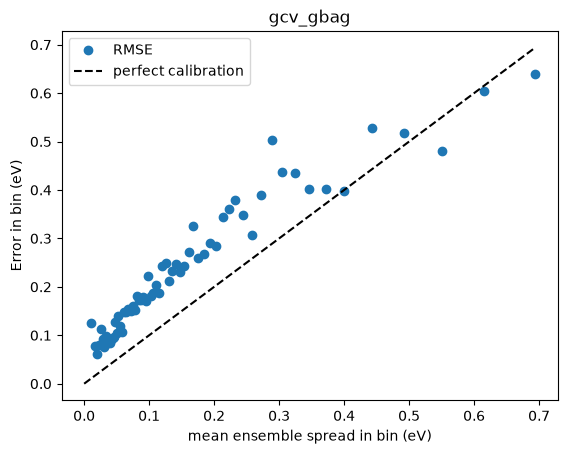

rcv_gbag
Spearman rho AE = 0.65
Spearman rho RMSE = 0.65


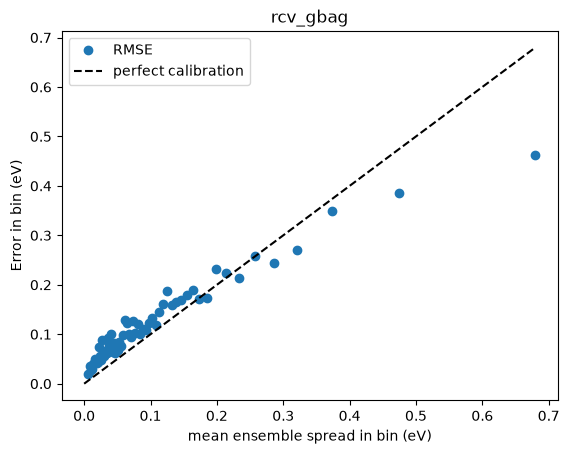

gcv_rbag
Spearman rho AE = 0.51
Spearman rho RMSE = 0.51


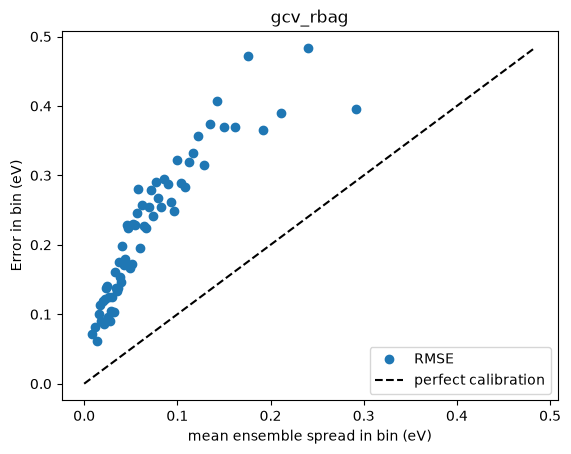

rcv_rbag
Spearman rho AE = 0.54
Spearman rho RMSE = 0.54


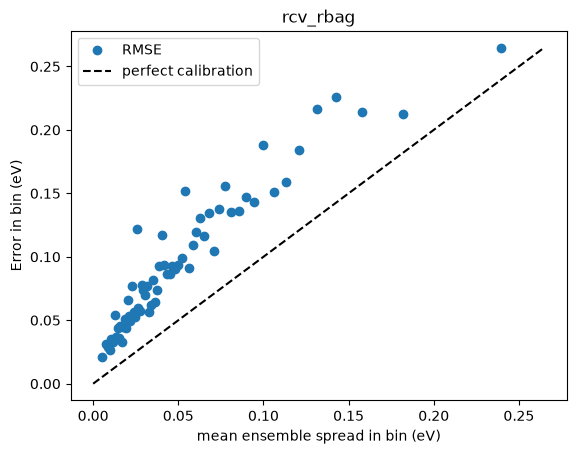

In [8]:
bs_list = [gcv_gbag, rcv_gbag, gcv_rbag, rcv_rbag]
bs_name = ['gcv_gbag', 'rcv_gbag', 'gcv_rbag', 'rcv_rbag']

n_bins = 65 # about 100x smaller than number of data, so about 100 points per bin

for i, res_dict in enumerate(bs_list):
    name = bs_name[i]
    print(name)
    pred_mean = res_dict['pred']
    pred_spread = res_dict['spread']
    pred_fold = res_dict['fold']
    abs_err = np.abs(pred_mean-y_target) # calculate AE
    sq_err = (pred_mean-y_target)**2
    rmse = np.sqrt(sq_err)
    rho_AE, p_AE = spearmanr(pred_spread, abs_err)
    print(f'Spearman rho AE = {rho_AE:.2f}')
    rho_RMSE, p_RMSE = spearmanr(pred_spread, rmse)
    print(f'Spearman rho RMSE = {rho_RMSE:.2f}')

    # returns an array of indices that, when used to index the original array, will produce a sorted version of that array.
    order = np.argsort(pred_spread)
    # splits the array of indices into n_bins number of groups
    sorted_bins = np.array_split(order, n_bins)
    # sorted_bins = order

    # here we generate the binned spread and rmse values, in increasing spread values (bins)
    bin_spread = [pred_spread[b].mean() for b in sorted_bins]
    bin_rmse = [np.sqrt(np.mean((pred_mean[b]-y_target[b])**2)) for b in sorted_bins]
    bin_mae = [np.mean(np.abs(pred_mean[b]-y_target[b])) for b in sorted_bins]
    
    # plt.scatter(bin_spread, bin_rmse, 'o-')
    plt.plot(bin_spread, bin_rmse, 'o', label = 'RMSE')
    # plt.plot(bin_spread, bin_mae, 'o', label = 'MAE')
    lim = max(max(bin_spread), max(bin_rmse))
    plt.plot([0, lim], [0, lim], 'k--', label='perfect calibration')
    # plt.plot([-100, 100], [-100, 100], 'k--', label='perfect calibration')
    # plt.xlim([0,0.8])
    # plt.ylim([0,0.8])
    plt.xlabel('mean ensemble spread in bin (eV)')
    plt.ylabel('Error in bin (eV)')
    plt.title(name)
    plt.legend()
    plt.savefig('Figures/2_calibration_spread_bin_'+name+'.png')
    plt.show()

In [9]:
# check how many compositions have predicted values within 1 stdev of the true value

In [10]:
bs_list = [gcv_gbag, rcv_gbag, gcv_rbag, rcv_rbag]
bs_name = ['gcv_gbag', 'rcv_gbag', 'gcv_rbag', 'rcv_rbag']


for i, res_dict in enumerate(bs_list):
    name = bs_name[i]
    print('----------')

    print(name)
    pred_mean = res_dict['pred']
    pred_spread = res_dict['spread']
    pred_fold = res_dict['fold']
    abs_err = np.abs(pred_mean-y_target) # calculate AE
    within_1 = np.mean(abs_err <= pred_spread) # abs_err<=pred_spread outputs an array of True/False. 
                                             # np.mean() turns converts True/False to 1/0, 
                                             # and the mean is the percentage of Trues in decimal
    within_2 = np.mean(abs_err <= 2*pred_spread)
    print(f'1σ {within_1*100:.2f}%, 2σ {within_2*100:.2f}%')
    print('----------')

----------
gcv_gbag
1σ 47.83%, 2σ 77.40%
----------
----------
rcv_gbag
1σ 59.36%, 2σ 85.01%
----------
----------
gcv_rbag
1σ 34.02%, 2σ 58.55%
----------
----------
rcv_rbag
1σ 48.14%, 2σ 76.41%
----------


Let's look at how the spread and rmse compares in each individual group

In [11]:
# create new dataframes that groups by B_pair, and calculates the MAE and mean spread for each group
ens_groups = ['gcv_gbag', 'rcv_gbag', 'gcv_rbag', 'rcv_rbag']


test_df = ensemble_df.copy()

per_pair_df_list = {}

for i, ens_group in enumerate(ens_groups):
    test_df[ens_group+'_err'] = test_df[ens_group+'_pred']-test_df['Eg_true']
    test_df[ens_group+'_abs_err'] = np.abs(test_df[ens_group+'_err'])
    test_df[ens_group+'_sq_err'] = test_df[ens_group+'_err']**2

    per_pair_df_list[ens_group] = test_df.groupby('B_pair').agg(mse=(ens_group+'_sq_err', 'mean'),
                                                                mae=(ens_group+'_abs_err', 'mean'), 
                                                                mean_spread=(ens_group+'_spread', 'mean'),
                                                                n=(ens_group+'_sq_err', 'size'))
    per_pair_df_list[ens_group]['rmse'] = np.sqrt(per_pair_df_list[ens_group]['mse'])

gcv_gbag
Spearman rho = 0.76


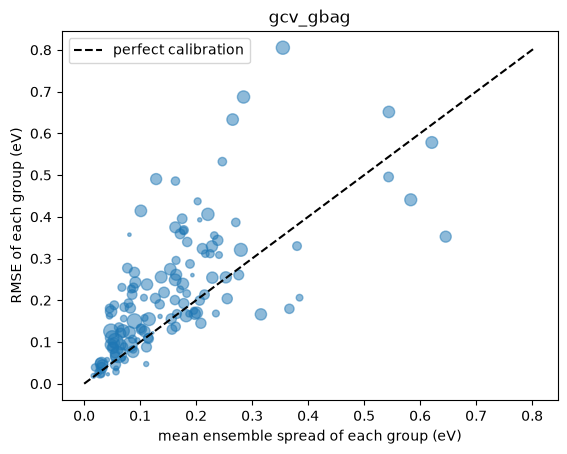

rcv_gbag
Spearman rho = 0.91


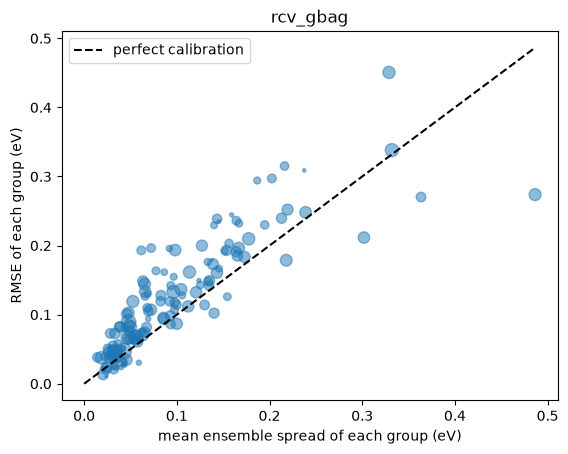

gcv_rbag
Spearman rho = 0.75


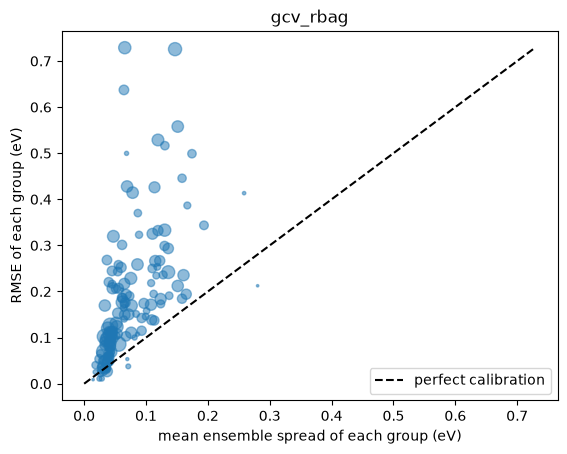

rcv_rbag
Spearman rho = 0.87


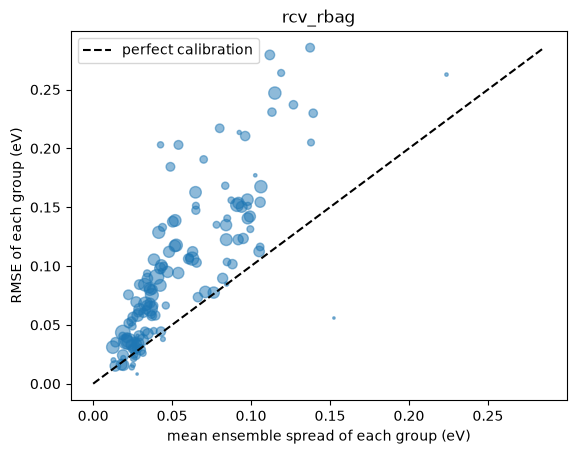

In [12]:
ens_groups = ['gcv_gbag', 'rcv_gbag', 'gcv_rbag', 'rcv_rbag']


for i, ens_group in enumerate(ens_groups):
    name = ens_group
    print(name)
    df = per_pair_df_list[ens_group]

    group_mae = df['mae']
    group_mse = df['mse']
    group_rmse = df['rmse']
    group_mean_spread = df['mean_spread']
    n_members = df['n']
    rho, p = spearmanr(group_mean_spread, group_rmse)
    print(f'Spearman rho = {rho:.2f}')

    # plt.scatter(bin_spread, bin_rmse, 'o-')
    plt.scatter(group_mean_spread, group_rmse, s = n_members, alpha = 0.5)
    lim = max(max(group_mean_spread), max(group_rmse))
    plt.plot([0, lim], [0, lim], 'k--', label='perfect calibration')
    plt.xlabel('mean ensemble spread of each group (eV)')
    plt.ylabel('RMSE of each group (eV)')
    plt.title(name)
    plt.legend()
    plt.savefig('Figures/2_calibration_Bpair_'+name+'.png')
    plt.show()

In [13]:
df = per_pair_df_list['gcv_gbag']
df['ratio'] = df['rmse'] / df['mean_spread']
print(df.sort_values('ratio', ascending=False).head(10))
print(df.sort_values('ratio', ascending=True).head(10))

             mse       mae  mean_spread   n      rmse     ratio
B_pair                                                         
Mg-Pd   0.127544  0.264116     0.080833   6  0.357133  4.418138
Mg-V    0.171550  0.303492     0.101281  69  0.414186  4.089480
Ba-V    0.032485  0.107420     0.045552  39  0.180237  3.956700
Cd-Sn   0.240429  0.390659     0.128551  63  0.490336  3.814328
Fe-Mn   0.029864  0.113591     0.048066  67  0.172812  3.595291
Pd-nan  0.026362  0.088569     0.045257  20  0.162362  3.587601
Co-V    0.076728  0.272413     0.077252  48  0.276998  3.585625
Ba-Ni   0.035325  0.104037     0.053766  40  0.187950  3.495722
Ni-nan  0.053285  0.153498     0.067404  32  0.230835  3.424649
Pb-Zn   0.235760  0.437912     0.163018  36  0.485551  2.978510
             mse       mae  mean_spread   n      rmse     ratio
B_pair                                                         
Co-Pt   0.002222  0.042978     0.110792  13  0.047135  0.425434
Cu-nan  0.032208  0.158529     0.366498 

1. Load saved table 'Eg_XGB_ensemble_pred_spread.csv'

2. Ranking: Spearmanr for all four runs. Do higher-spread correlate with higher errors?

3. Calibration plots: binned spread vs. RMSE. Are the spread values the right magnitude compared to errors? Parity plots (error vs uncertainty) should be helpful here. Points above the diagonal mean overconfident (uncertainty lower than error); below means underconfident (uncertainty higher than error).

4. Coverage: one more number per run. The fraction of compositions whose target value falls within 1 or 2 spread of the ensemble mean prediction. If errors were roughly normal and the spread well calibrated, you’d expect about 68% and 95%. How often does the prediction+spread match the true target value?

5. Per-B-pair check (from the schedule). Average the absolute error and the spread within each B-pair, using the grouped CV runs. Plot one point per pair. Answers: does the ensemble flag the chemistries it gets most wrong? This also sets up Week 4’s per-chemistry analysis.

6. Optional: recalibration. Find the single scale factor that brings the spread onto the diagonal, as in Palmer et al. (2022). The pitfall is circularity: fitting the factor on the same predictions you evaluate makes it look perfect. Fit it on four folds’ predictions and test it on the fifth, rotating through all five. Skip this if time is short; tasks 2–5 are the deliverable.

7. Write-up. An interpretation paragraph in the README, and commit.

In [14]:
# LOGO cv
cv_logo = LeaveOneGroupOut()

In [15]:
model_xgb = xgb.XGBRegressor

In [16]:
def run_cross_validation(model, X, y, cv, groups=None, random_state=None, return_estimator=False):
    model_cv = model(random_state=random_state)
    if groups is None:
        result = cross_validate(model_cv, X, y, cv = cv, scoring = 'neg_mean_absolute_error', 
                                return_train_score = True, return_estimator=return_estimator)
    else:
        result = cross_validate(model_cv, X, y, cv = cv, groups = groups, scoring = 'neg_mean_absolute_error',
                                 return_train_score = True, return_estimator=return_estimator)
    return result

def print_cv_results(cv_results, cv_name=str):
    print(f"{cv_name} CV results:")
    print(f"MAE: {-1 * cv_results['test_score'].mean():.3f} +/- {cv_results['test_score'].std():.3f}")
    print(f"per-fold: {np.round(-1 * cv_results['test_score'], 3)}")
    print(f"runtime: {cv_results['fit_time'].sum() + cv_results['score_time'].sum():.2f} s total")

In [17]:
my_df = pd.read_parquet('../parquet/composition_feature_matrix.parquet')

# let's assign a label that groups the alloys by their B1 and B2 site.
# we want to make sure that (B1, B2) of (Ni, Co) is the same as (Co, Ni), so we should sort the pair
my_df['B_pair'] = my_df[['B1','B2']].apply(
    lambda r: '-'.join(sorted([str(r['B1']), str(r['B2'])])), axis=1) # this is a lambda function that applies the sorted labeling

# these are the non-feature columns in the dataframe, which we will drop before training the model
non_feature_cols = ['formula', 'alloy_id', 'A1', 'A2', 'B1', 'B2', 'X', 'is_alloy', 'x_frac', 'Eg', 'dHf', 'dHd', 'B_pair']

In [18]:
# convert the dataframe to a numpy array
X = my_df.drop(columns=non_feature_cols).values

# grab the target columns, Eg and dHd, and convert them to numpy arrays
y_elec = my_df['Eg'].values
y_stab = my_df['dHd'].values
# let's start with band gaps
y = y_elec

In [19]:
xgb_cv_grouped_logo_res = run_cross_validation(xgb.XGBRegressor, X, y, cv_logo, groups=my_df['B_pair'], random_state = seed)

In [20]:
print('----------------------------------------------')
print('XGBoost Results')
print('----------------------------------------------')
print_cv_results(xgb_cv_grouped_logo_res, cv_name="Grouped LOGO")
print('----------------------------------------------')

----------------------------------------------
XGBoost Results
----------------------------------------------
Grouped LOGO CV results:
MAE: 0.143 +/- 0.121
per-fold: [0.106 0.175 0.064 0.068 0.055 0.049 0.169 0.146 0.115 0.149 0.216 0.153
 0.049 0.107 0.108 0.16  0.198 0.068 0.041 0.035 0.061 0.182 0.078 0.109
 0.132 0.316 0.222 0.123 0.044 0.088 0.22  0.145 0.104 0.05  0.021 0.083
 0.283 0.621 0.125 0.168 0.262 0.365 0.082 0.053 0.226 0.155 0.379 0.089
 0.062 0.023 0.097 0.046 0.06  0.155 0.03  0.079 0.047 0.268 0.099 0.06
 0.016 0.084 0.092 0.016 0.121 0.066 0.038 0.237 0.075 0.066 0.029 0.033
 0.124 0.042 0.009 0.023 0.02  0.054 0.043 0.077 0.144 0.021 0.119 0.103
 0.038 0.133 0.03  0.568 0.186 0.336 0.249 0.286 0.126 0.082 0.281 0.238
 0.275 0.121 0.436 0.413 0.092 0.028 0.257 0.597 0.297 0.165 0.135 0.095
 0.089 0.118 0.131 0.182 0.073 0.099 0.086 0.285 0.092 0.086 0.147 0.517
 0.077 0.01  0.144 0.081 0.159 0.278 0.242 0.035 0.069 0.171 0.133 0.036
 0.34  0.056 0.371]
runtime: 68.